# Free energy / late-state population comparison across all PBMetaD CV combinations

Compares all five SI-relevant PBMetaD collective-variable (CV) combinations
(`ANALYSIS_RULES.md` Sec. 5, `PLOTTING_STYLE.md`) against each other on the same
two metrics: the late-block, bias-reweighted **free energy** and **population**
of each of the 8 backbone conformer states (`ccc`...`ttt`).

- **META-OPH, META-OPP, META-OPPC**: single-replica runs, from
  `single_trajectory_state_analysis/<ophi|ophps|oppc>/<...>_late_state_summary.csv`.
  No replicate spread, so no error bar (same convention as HREX/REDS single-trajectory
  metrics elsewhere in this project) -- only the std across the late blocks used for
  the free-energy/population estimate itself.
- **META-OMG8REP, META-OPPC8REP**: 8-replica ensembles, from
  `<omega|oppc>_state_analysis/state_analysis_results/all_replicas_late_population_average.csv`
  (mean) and `all_replicas_late_results.csv` (per-replica, for the across-replica SEM).

This extends the existing `single_trajectory_state_analysis.ipynb` comparison --
which already plots free energy/population for the 4 single-trajectory CVs
(omega, ophi, ophps, oppc) side by side with their 8-replica ensemble counterpart
in a 2-row "single trajectory vs. ensemble" grid, using ad hoc `tab10` state
colors local to that notebook -- with a single 5-panel-equivalent, grouped-bar
comparison across *all* CV variants together (mirroring the
`stationary_population_8_conform.ipynb` / `plot_pub_full_column`-style grouped-bar
convention used for cross-method comparisons elsewhere in `Analysis/`), using the
project's canonical `STATE_COLORS`/`STATE_ORDER` from `Analysis/plotting_style.py`
so this figure's state colors match every other per-state-colored figure in the
paper. See `Analysis/README.md` and `Metadynamics/analysis/README.md` for the
rest of the pipeline these numbers come from.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("../../Analysis"))
from plotting_style import METHOD_COLORS, STATE_COLORS, STATE_ORDER, TICK_FONTSIZE, LEGEND_FONTSIZE

STATE_ORDER_ALPHA = [s.upper() for s in STATE_ORDER]
CV_ORDER = ["META-OPH", "META-OPP", "META-OPPC", "META-OMG8REP", "META-OPPC8REP"]

## Load each CV variant's late-block free energy and population

In [2]:
SINGLE_TRAJ_DIR = "single_trajectory_state_analysis"
SINGLE_CV_FOLDERS = {"META-OPH": "ophi", "META-OPP": "ophps", "META-OPPC": "oppc"}
REPLICA_CV_FOLDERS = {"META-OMG8REP": "omega", "META-OPPC8REP": "oppc"}


def load_single_traj_cv(folder):
    """Single-replica CV: late-block free energy/population, std across blocks
    only (no replicate spread available for a single trajectory)."""
    df = pd.read_csv(f"{SINGLE_TRAJ_DIR}/{folder}/{folder}_late_state_summary.csv").set_index("state").reindex(STATE_ORDER_ALPHA)
    return {
        "free_energy": df["free_energy"].to_numpy(),
        "free_energy_err": None,
        "population": df["population"].to_numpy(),
        "population_err": df["population_std_across_blocks"].to_numpy(),
    }


def load_replica_cv(folder):
    """8-replica ensemble CV: late-block free energy/population (mean across
    replicas), with the across-replica SEM as the error bar for both."""
    avg = pd.read_csv(f"{folder}_state_analysis/state_analysis_results/all_replicas_late_population_average.csv").set_index("state").reindex(STATE_ORDER_ALPHA)
    per_replica = pd.read_csv(f"{folder}_state_analysis/state_analysis_results/all_replicas_late_results.csv")
    fe_sem = per_replica.groupby("state")["free_energy"].sem().reindex(STATE_ORDER_ALPHA)
    return {
        "free_energy": avg["free_energy"].to_numpy(),
        "free_energy_err": fe_sem.to_numpy(),
        "population": avg["population"].to_numpy(),
        "population_err": avg["population_sem_across_replicas"].to_numpy(),
    }


cv_data = {name: load_single_traj_cv(folder) for name, folder in SINGLE_CV_FOLDERS.items()}
cv_data.update({name: load_replica_cv(folder) for name, folder in REPLICA_CV_FOLDERS.items()})
{name: d["free_energy"].round(2).tolist() for name, d in cv_data.items()}

{'META-OPH': [7.01, 7.67, 7.02, 5.66, 4.93, 4.29, 4.01, 3.87],
 'META-OPP': [5.37, 6.12, 9.29, 6.98, 4.32, 3.13, 5.55, 4.86],
 'META-OPPC': [6.58, 6.41, 6.11, 5.85, 4.6, 4.64, 4.59, 4.05],
 'META-OMG8REP': [6.34, 5.87, 6.88, 6.71, 4.64, 3.65, 4.94, 4.41],
 'META-OPPC8REP': [6.59, 7.01, 7.33, 6.36, 4.67, 3.49, 4.78, 4.14]}

## Grouped-bar comparison, colored by CV variant (`METHOD_COLORS`)

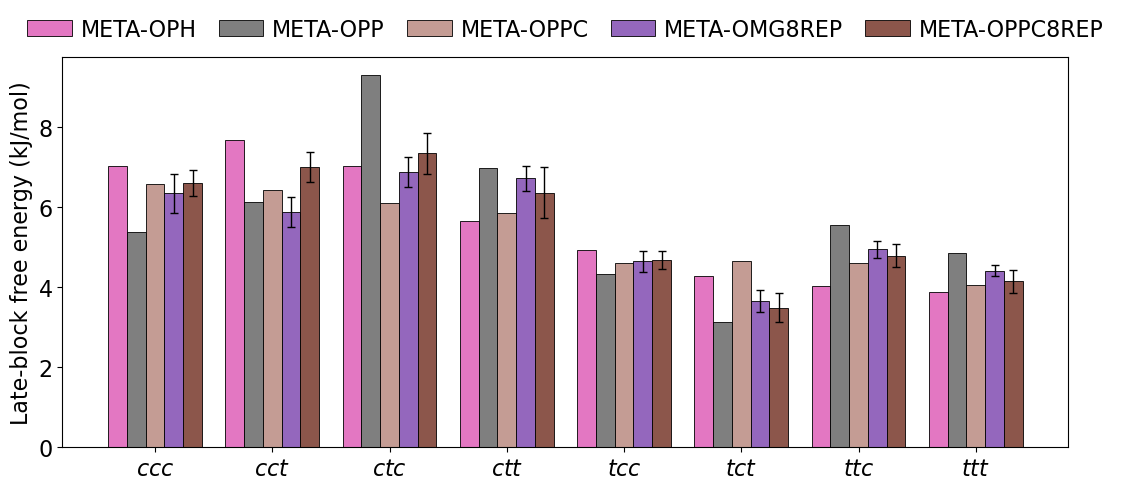

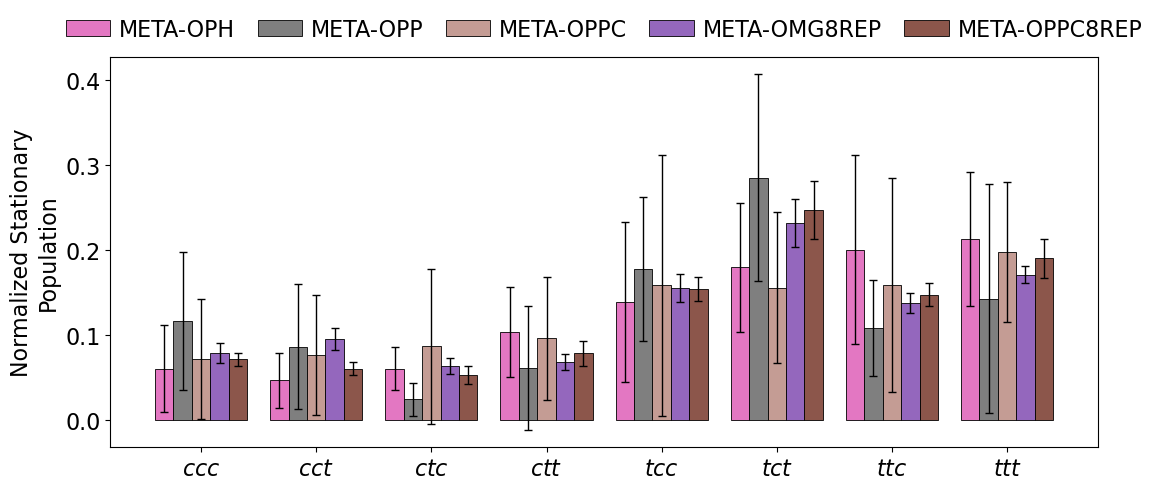

In [3]:
os.makedirs("fig", exist_ok=True)


def plot_cv_grouped_bar(metric, ylabel, savepath, figsize=(12, 5)):
    """One grouped bar chart: x = 8 conformer states, one bar per CV variant
    (colored by METHOD_COLORS) within each state group -- mirrors the
    plot_pub_full_column grouped-bar convention used for cross-method
    comparisons in Analysis/Analysis_8_state_population.ipynb, applied here to
    the 5 PBMetaD CV variants instead of the 6 sampling methods."""
    x = np.arange(len(STATE_ORDER))
    n = len(CV_ORDER)
    bar_width = 0.8 / n

    fig, ax = plt.subplots(figsize=figsize)
    for j, name in enumerate(CV_ORDER):
        vals = cv_data[name][metric]
        errs = cv_data[name][f"{metric}_err"]
        offset = (j - (n - 1) / 2) * bar_width
        ax.bar(
            x + offset, vals, bar_width, label=name, yerr=errs, capsize=3.0,
            error_kw={'elinewidth': 1.0, 'capthick': 1.0},
            color=METHOD_COLORS[name], edgecolor="black", linewidth=0.6,
        )

    ax.set_xticks(x)
    ax.set_xticklabels([fr"$\mathit{{{s}}}$" for s in STATE_ORDER], fontsize=14)
    ax.set_ylabel(ylabel, fontsize=16)
    ax.tick_params(axis='both', which='major', labelsize=TICK_FONTSIZE)
    ax.legend(
        loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=n, fontsize=LEGEND_FONTSIZE,
        frameon=False, columnspacing=1.0, handletextpad=0.4,
    )

    plt.tight_layout()
    plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()


plot_cv_grouped_bar("free_energy", "Late-block free energy (kJ/mol)", "fig/free_energy_all_cv_comparison.png")
plot_cv_grouped_bar("population", "Normalized Stationary\nPopulation", "fig/late_population_all_cv_comparison.png")

## Per-CV-panel view, colored by conformer state (`STATE_COLORS`)

The opposite color dimension from the grouped-bar figures above -- one panel per
CV variant, 8 conformer-state bars colored by `STATE_COLORS` within each panel --
matching the per-method-panel convention used everywhere else in this project for
a per-state breakdown (e.g. `stationary_population_8_conform.ipynb`'s
`plot_method_grid`, and the population/error-over-time SI sections added
alongside it in `Analysis/`).

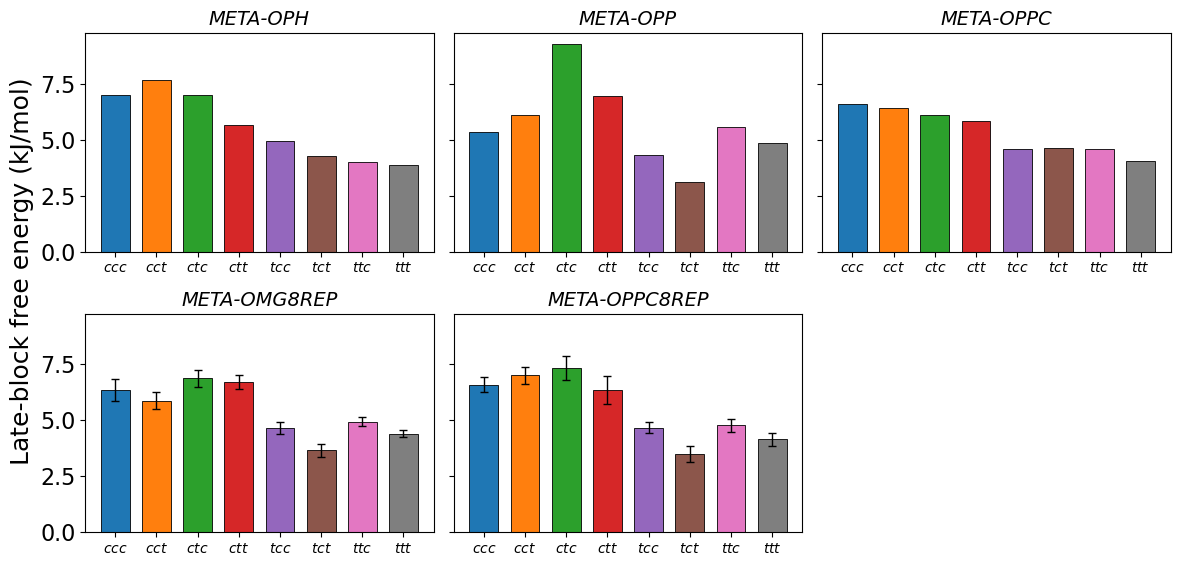

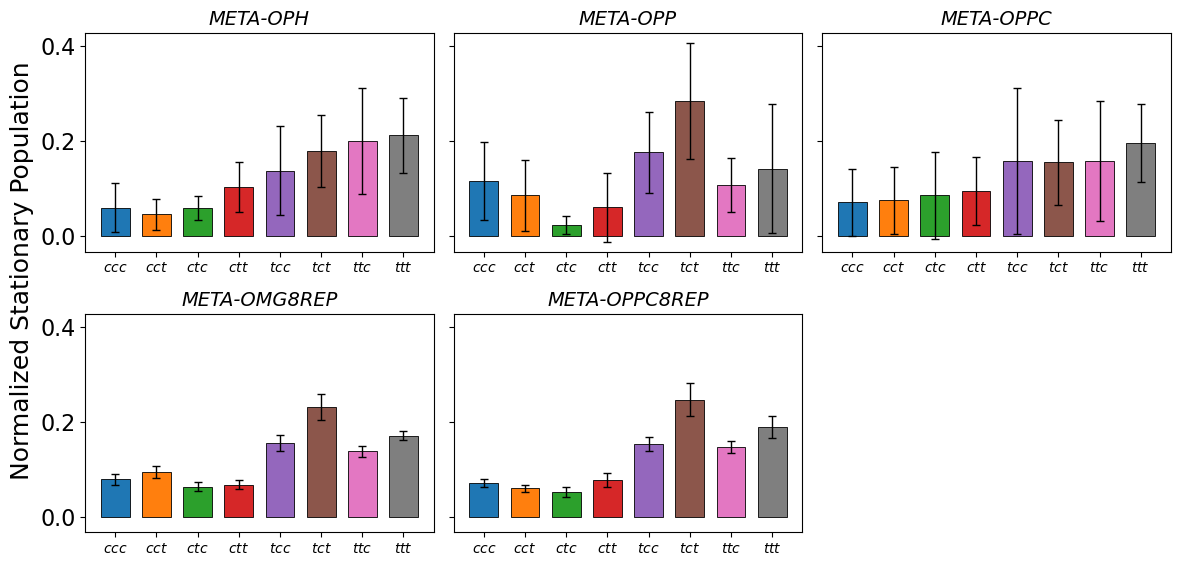

In [4]:
def plot_cv_panel_bar(metric, ylabel, savepath, ncols=3, figsize_per_panel=(4, 3)):
    nrows = -(-len(CV_ORDER) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per_panel[0] * ncols, figsize_per_panel[1] * nrows), sharey=True)
    axes = np.atleast_1d(axes).flatten()

    x = np.arange(len(STATE_ORDER))
    for idx, name in enumerate(CV_ORDER):
        ax = axes[idx]
        vals = cv_data[name][metric]
        errs = cv_data[name][f"{metric}_err"]
        colors = [STATE_COLORS[s] for s in STATE_ORDER]
        ax.bar(x, vals, 0.7, yerr=errs, capsize=3.0, error_kw={'elinewidth': 1.0, 'capthick': 1.0},
               color=colors, edgecolor="black", linewidth=0.6)
        ax.set_xticks(x)
        ax.set_xticklabels([fr"$\mathit{{{s}}}$" for s in STATE_ORDER], fontsize=10, rotation=0)
        ax.set_title(name, fontstyle='italic', fontsize=14)
        ax.tick_params(axis='y', which='major', labelsize=TICK_FONTSIZE)

    for idx in range(len(CV_ORDER), len(axes)):
        axes[idx].axis("off")

    fig.supylabel(ylabel, fontsize=18)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()


plot_cv_panel_bar("free_energy", "Late-block free energy (kJ/mol)", "fig/free_energy_all_cv_per_panel.png")
plot_cv_panel_bar("population", "Normalized Stationary Population", "fig/late_population_all_cv_per_panel.png")